# Aula 3 — Análise exploratória: PCA e correlação de Pearson
**Módulo `geocis_espectral.exploratoria`**

**Perguntas desta aula**
1. Quantas "direções" independentes de variação existem em ~2000 bandas? (PCA)
2. Quais amostras são atípicas? (distância de Mahalanobis nos PCs)
3. Quais bandas se relacionam com cada atributo? (correlograma de Pearson)
4. O que cada PC representa em termos de solo? (correlação PCs × atributos)

In [1]:
# --- Configuração (igual em todas as aulas) ---------------------------------
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from geocis_espectral import dados, visualizacao as vz, processamento as pp
from geocis_espectral import exploratoria as ex, agrupamento as ag, modelagem as mo

vz.set_style()
pd.set_option("display.max_columns", 30)

# Base do GeoCiS: raw_nir_data_Saturin.csv + raw_mir_data_Saturin.csv.
# Na 1ª execução (ou se os CSV mudarem) a base pareada é preparada automaticamente (~30 s).
# Para demonstrações fora do GeoCiS, troque para FONTE = "synthetic".
FONTE = "paired"
ds = dados.load_dataset(FONTE)
ds

SoilSpectra(n=6230, vnir=2151 bandas [350-2500 nm], mir=851 bandas [4000-600 cm-1])

In [2]:
X = pp.snv(pp.trim(ds.vnir, 400, 2450))     # VIS-NIR-SWIR sem bordas, com SNV
atributos = ds.attributes.loc[:, ds.attributes.notna().sum() > 300]   # atributos com n suficiente
atributos.columns.tolist()

['Sand_gkg',
 'Silt_gkg',
 'Clay_gkg',
 'Density_kgdm3',
 'C_gkg',
 'P_mgkg',
 'pH_H2O',
 'Ca_mmolkg',
 'Mg_mmolkg',
 'K_mmolkg',
 'CEC_Ph7_mmolkg',
 'CEC_Efe_mmolkg',
 'MacroN_g_kg']

## 1. PCA
A PCA rotaciona as bandas (altamente correlacionadas) em componentes **não correlacionados**,
ordenados pela variância. Em espectros, poucos PCs concentram quase toda a variação.
- **Escores**: posição de cada amostra no novo sistema → mapas de amostras;
- **Loadings**: peso de cada banda no PC → *onde* no espectro o PC "olha".

Usamos PCA **centrada, sem padronizar** as bandas (todas na mesma unidade).

In [3]:
pca = ex.run_pca(X, n_components=10)
print("PCs para 99% da variância:", ex.n_components_for(pca.explained, 0.99))
pca.summary().head(6)

PCs para 99% da variância: 10


,variancia_%,acumulada_%
PC1,62.78,62.78
PC2,16.80,79.58
PC3,7.38,86.96
PC4,4.62,91.58
PC5,3.37,94.95
PC6,1.30,96.25


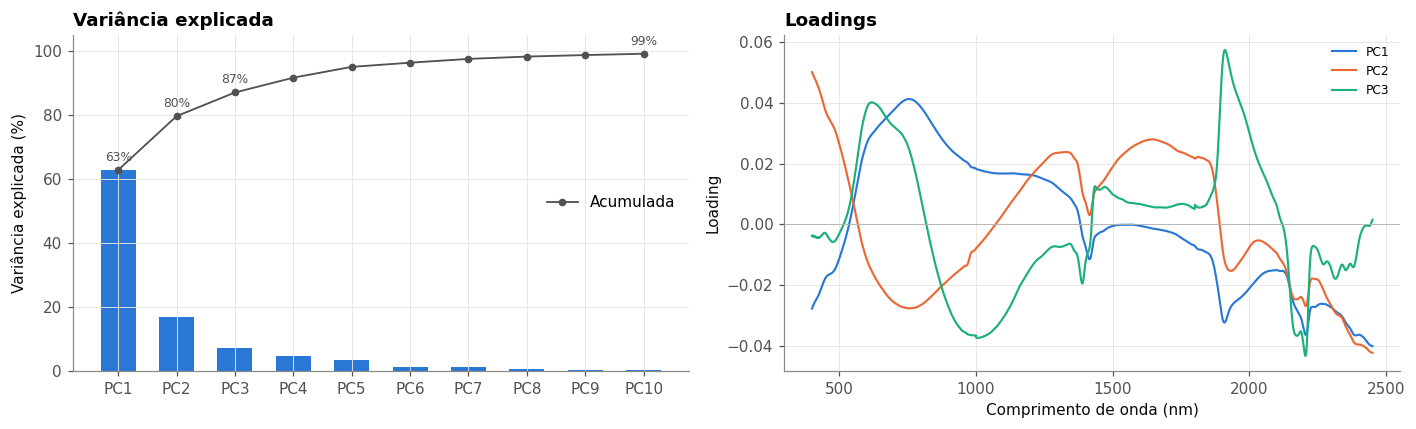

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
vz.plot_scree(pca.explained, ax=axes[0])
vz.plot_loadings(pca.loadings, pcs=(1, 2, 3), ax=axes[1])
axes[1].set_title("Loadings", loc="left"); axes[0].set_title("Variância explicada", loc="left")
fig.tight_layout()

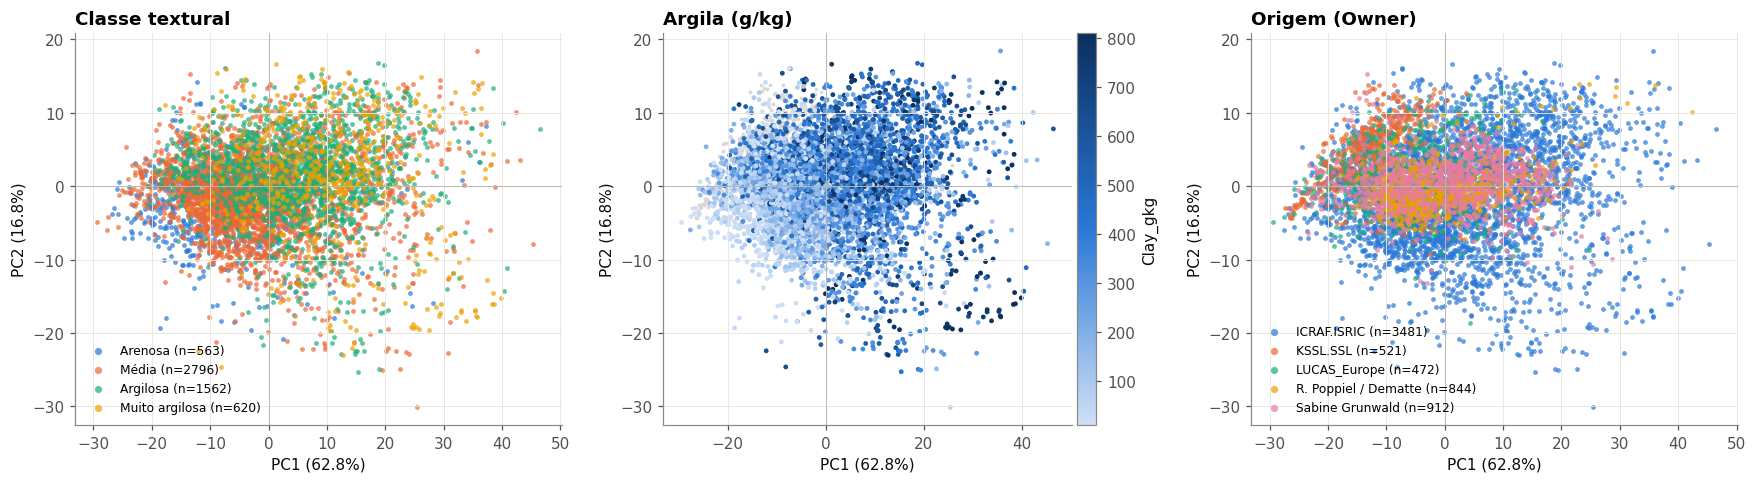

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
vz.plot_scores(pca.scores, color_by=ds.meta["Textura"], explained=pca.explained, ax=axes[0], title="Classe textural")
vz.plot_scores(pca.scores, color_by=ds.meta["Clay_gkg"], explained=pca.explained, ax=axes[1], title="Argila (g/kg)")
vz.plot_scores(pca.scores, color_by=ds.meta["Owner"], explained=pca.explained, ax=axes[2], title="Origem (Owner)")
fig.tight_layout()

**Interpretação:** se as amostras se separam por **Owner** mais do que por solo, há efeito de
equipamento/protocolo — o problema que protocolos como o *SQuaP* (Bartsch et al.) e a
padronização com amostras de referência (ex.: Lucky Bay) procuram resolver. Fique atento ao
juntar bibliotecas diferentes.

## 2. Outliers espectrais
Distância de Mahalanobis nos primeiros PCs comparada ao limite qui-quadrado (α = 1 %).
Outliers não devem ser removidos automaticamente — inspecione os espectros primeiro.

253 outliers (4.1%)


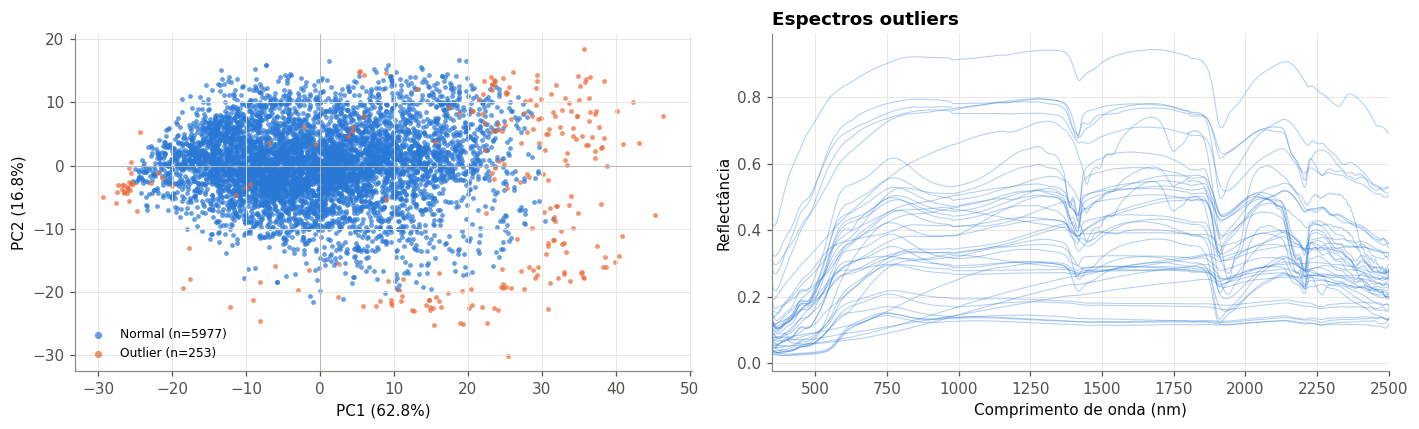

In [6]:
out = ex.mahalanobis_outliers(pca.scores, n_components=5, alpha=0.01)
print(f"{out['outlier'].sum()} outliers ({out['outlier'].mean():.1%})")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rotulo = out["outlier"].map({True: "Outlier", False: "Normal"}).astype("category")
vz.plot_scores(pca.scores, color_by=rotulo, explained=pca.explained, ax=axes[0])
if out["outlier"].any():
    vz.plot_spectra(ds.vnir.loc[out.index[out["outlier"]]], n_max=40, ax=axes[1], title="Espectros outliers")
fig.tight_layout()

## 3. Correlograma: r de Pearson banda × atributo
Para cada banda calculamos r com o atributo (usando apenas amostras com o valor medido).
Bandas com |r| alto indicam feições ligadas ao atributo. Para n grande, |r| > 0,05 já é
"significativo" — o que importa é a **magnitude** e a **coerência física**.

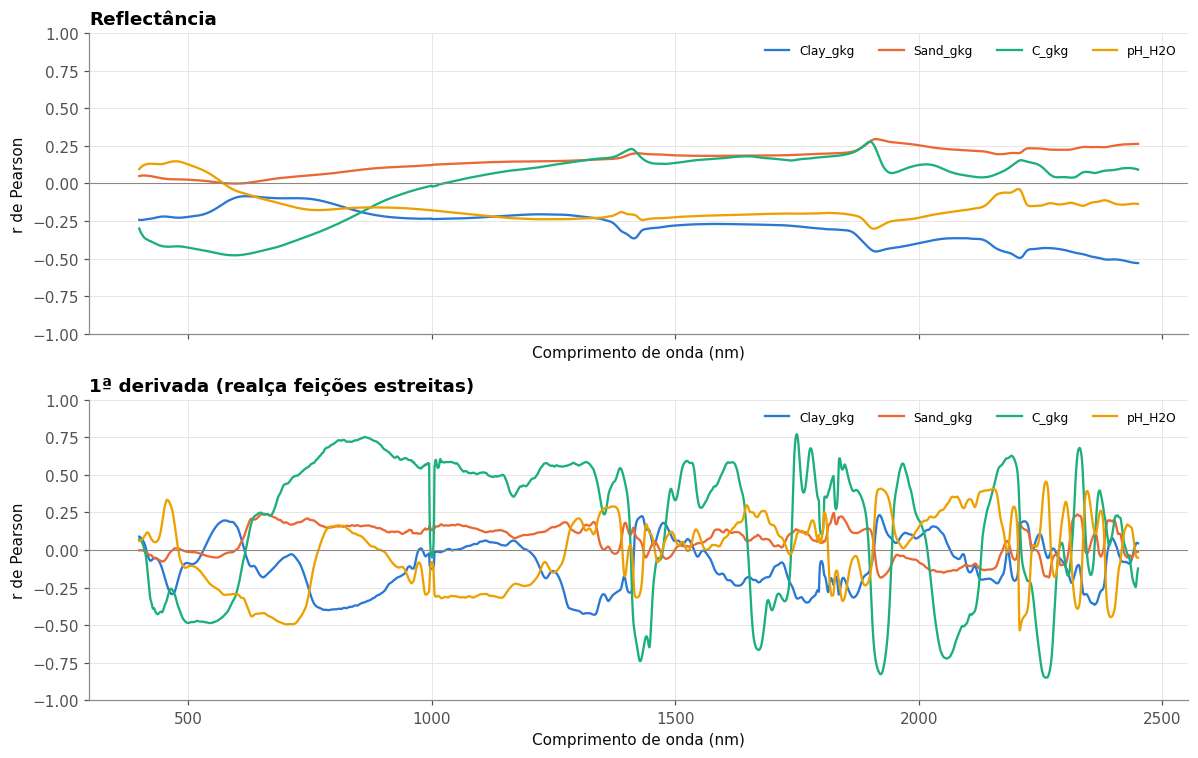

In [7]:
alvos = [c for c in ["Clay_gkg", "Sand_gkg", "C_gkg", "pH_H2O"] if c in atributos]
corr_bruto = ex.correlate_bands(pp.trim(ds.vnir, 400, 2450), atributos[alvos])
corr_deriv = ex.correlate_bands(pp.derivative(pp.trim(ds.vnir, 400, 2450), 1, 11), atributos[alvos])
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
vz.plot_correlogram(corr_bruto, ax=axes[0], title="Reflectância")
vz.plot_correlogram(corr_deriv, ax=axes[1], title="1ª derivada (realça feições estreitas)")
fig.tight_layout()

In [8]:
ex.top_bands(corr_deriv, "Clay_gkg", n=8, min_distance=30).round(3)

,banda,r
0,1334.0,-0.431
1,1304.0,-0.409
2,788.0,-0.401
3,818.0,-0.388
4,848.0,-0.369
5,2361.0,-0.365
6,758.0,-0.353
7,1771.0,-0.350


## 4. PCs × atributos: o que cada componente significa?
Matriz de r de Pearson; células com p ≥ 0,05 aparecem com "·".

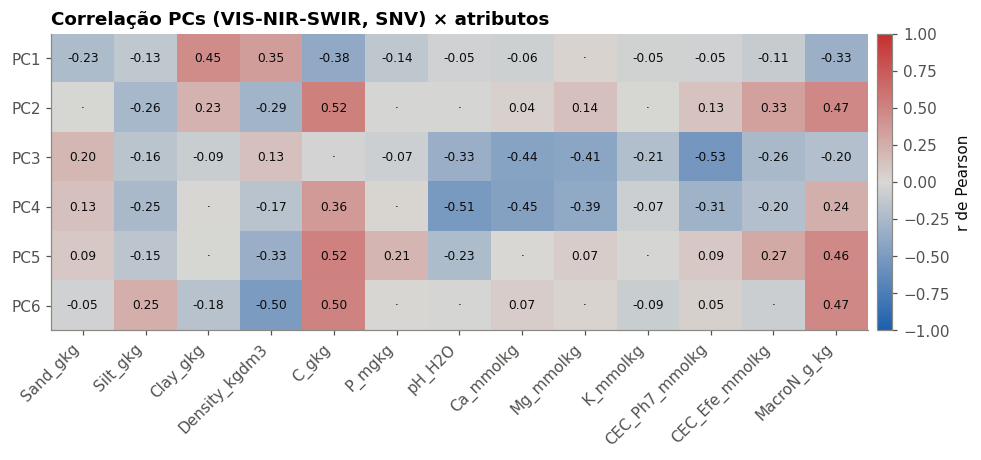

In [9]:
r, p, n = ex.correlate_with_attributes(pca.scores.iloc[:, :6], atributos)
ax = vz.plot_corr_matrix(r, pvalues=p, title="Correlação PCs (VIS-NIR-SWIR, SNV) × atributos")

## 5. O mesmo para o MIR

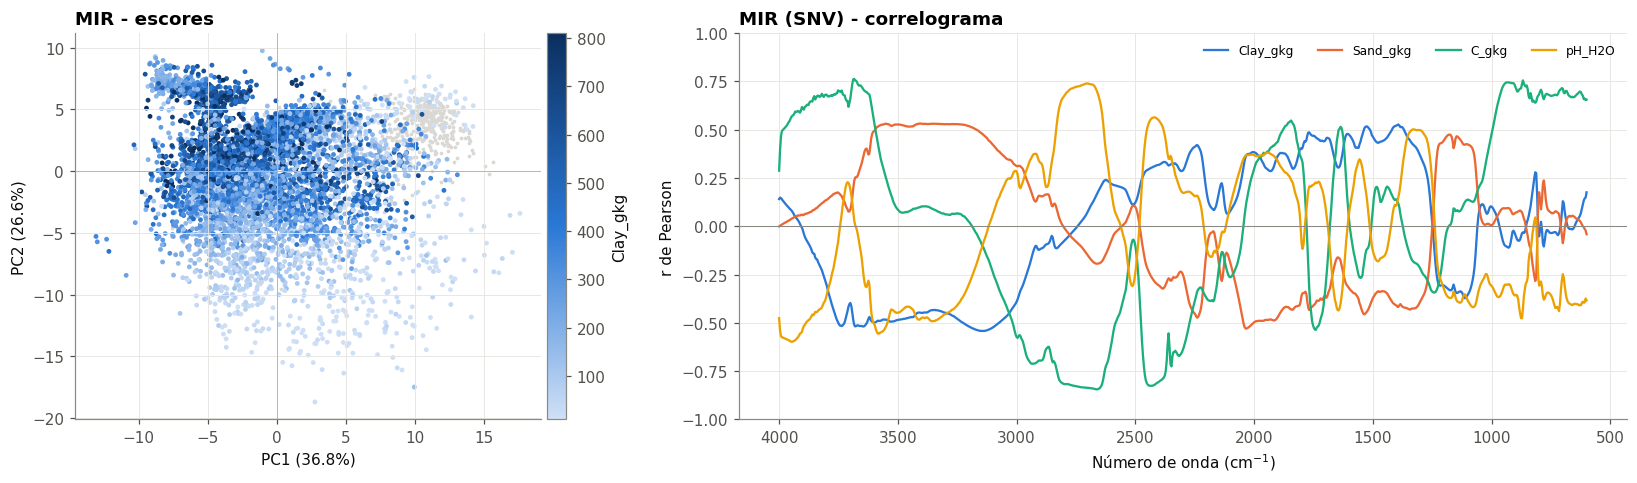

In [10]:
pca_mir = ex.run_pca(pp.snv(ds.mir), n_components=10)
corr_mir = ex.correlate_bands(pp.snv(ds.mir), atributos[alvos])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
vz.plot_scores(pca_mir.scores, color_by=ds.meta["Clay_gkg"], explained=pca_mir.explained, ax=axes[0], title="MIR - escores")
vz.plot_correlogram(corr_mir, ax=axes[1], title="MIR (SNV) - correlograma")
fig.tight_layout()

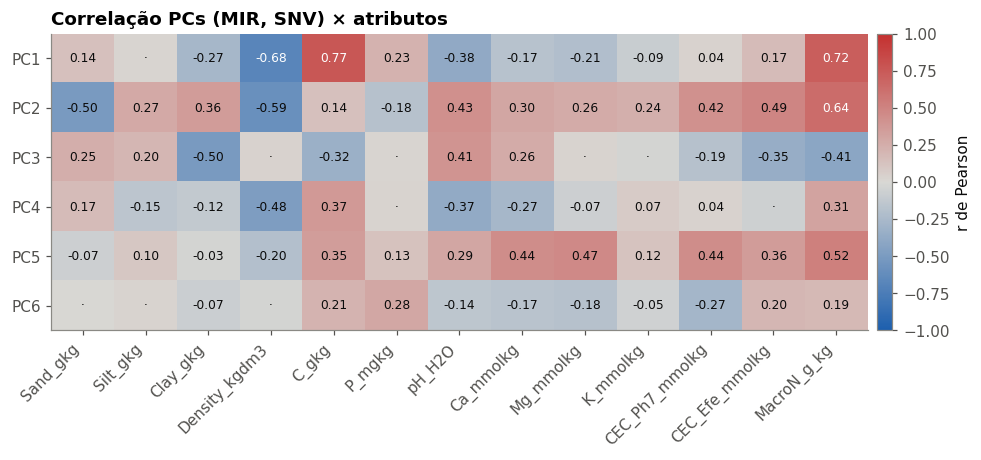

In [11]:
r_m, p_m, _ = ex.correlate_with_attributes(pca_mir.scores.iloc[:, :6], atributos)
ax = vz.plot_corr_matrix(r_m, pvalues=p_m, title="Correlação PCs (MIR, SNV) × atributos")

## Exercícios
1. Refaça a PCA **sem SNV**. O PC1 passa a representar o quê? (dica: correlacione com o albedo médio `ds.vnir.mean(axis=1)`).
2. Repita o correlograma com **remoção do contínuo**. Quais bandas ganham destaque para argila?
3. Projete as amostras de um único `Owner` com `pca.transform(...)` e compare com o restante.